# Notebook C — Placement (differentiable silhouette, preserves SF3D textures)
Run C0..C2. Set KEEP / YAW_OVERRIDE in C2 as needed.

In [1]:
# C0 — PyTorch3D + deps (compiles CUDA ~10-15 min). If it fails, placement uses a fast-silhouette fallback.
import torch
print("torch", torch.__version__, "| cuda", torch.version.cuda)
!pip install -q ninja fvcore iopath open3d==0.19.0 trimesh opencv-python-headless
!pip install -q "git+https://github.com/facebookresearch/pytorch3d.git@stable"
try:
    import pytorch3d; print("pytorch3d OK", pytorch3d.__version__)
except Exception as e:
    print("pytorch3d unavailable -> fallback will be used:", e)


torch 2.11.0+cu128 | cuda 12.8
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 4.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 4.4 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 447.7/447.7 MB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.7/180.7 kB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 741.0/741.0 kB 56.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.3/7.3 MB 127.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.8/139.8 kB 15.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 100.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 127.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
pytorch3d OK 0.7.8


In [ ]:
# # C1 — inputs: Notebook A outputs + SF3D meshes
# import os, zipfile, glob
# from google.colab import files
# OUT="/content/outputs"; os.makedirs(OUT, exist_ok=True)
# print("Upload notebookA_outputs.zip and meshes.zip (cancel if already in /content/outputs):")
# try:
#     for f in files.upload():
#         if f.endswith(".zip"):
#             with zipfile.ZipFile(f) as z: z.extractall("/content/outputs")
#             print("extracted", f)
# except Exception as e:
#     print("skip:", e)
# for dnm in ["clusters","masks","objects","meshes"]:
#     print(dnm, "->", len(glob.glob(f"{OUT}/{dnm}/*")))
# print("meta:", os.path.exists(f"{OUT}/meta.json"), "| floor:", os.path.exists(f"{OUT}/floor.ply"),
#       "| background:", os.path.exists(f"{OUT}/background_room.glb"))


Upload notebookA_outputs.zip and meshes.zip (cancel if already in /content/outputs):
skip: 'module' object is not iterable
clusters -> 0
masks -> 0
objects -> 0
meshes -> 0
meta: False | floor: False | background: False


In [1]:
import os, zipfile, glob

OUT = "/content/outputs"
os.makedirs(OUT, exist_ok=True)

# Find all zip files in /content (adjust path if needed)
zip_files = glob.glob("/content/*.zip")
if not zip_files:
    print("No zip files found in /content/")
else:
    for zip_path in zip_files:
        # Optionally filter only specific files (e.g., notebookA_outputs.zip, meshes.zip)
        # if not ("notebookA_outputs" in zip_path or "meshes" in zip_path):
        #     continue
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(OUT)
            print(f"Extracted {zip_path} -> {OUT}")

# Check contents
for dnm in ["clusters", "masks", "objects", "meshes"]:
    print(f"{dnm}: {len(glob.glob(f'{OUT}/{dnm}/*'))} files")
print("meta.json exists:", os.path.exists(f"{OUT}/meta.json"))
print("floor.ply exists:", os.path.exists(f"{OUT}/floor.ply"))
print("background_room.glb exists:", os.path.exists(f"{OUT}/background_room.glb"))

Extracted /content/notebookA_outputs.zip -> /content/outputs
Extracted /content/notebookB_meshes_raw.zip -> /content/outputs
clusters: 7 files
masks: 7 files
objects: 7 files
meshes: 0 files
meta.json exists: True
floor.ply exists: True
background_room.glb exists: True


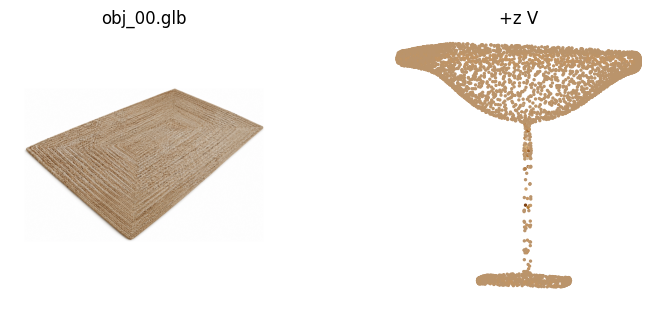

baked obj_00 +z


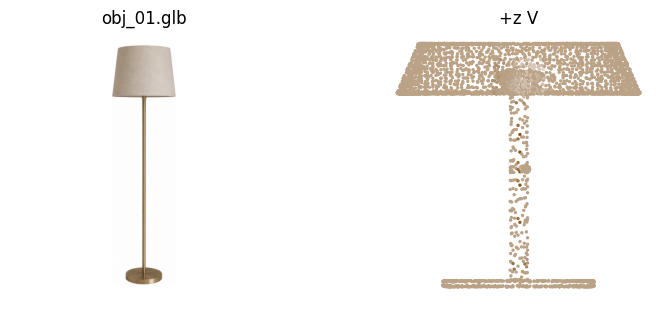

baked obj_01 +z


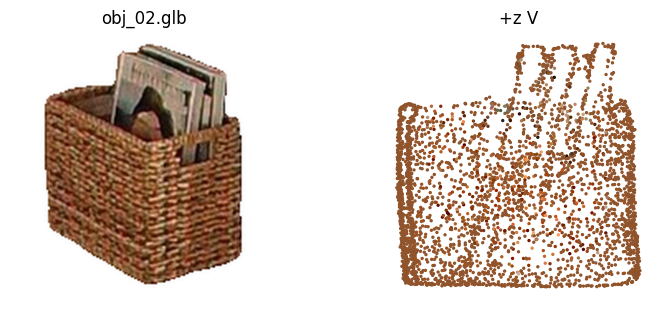

baked obj_02 +z


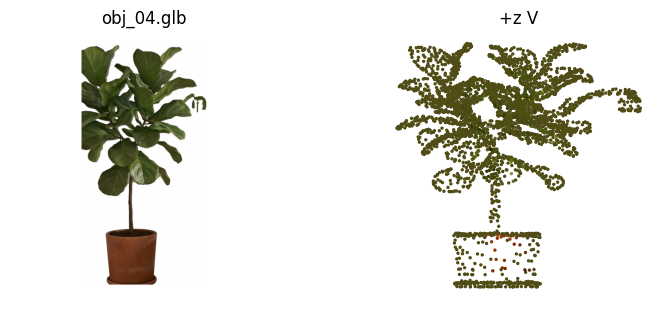

baked obj_04 +z


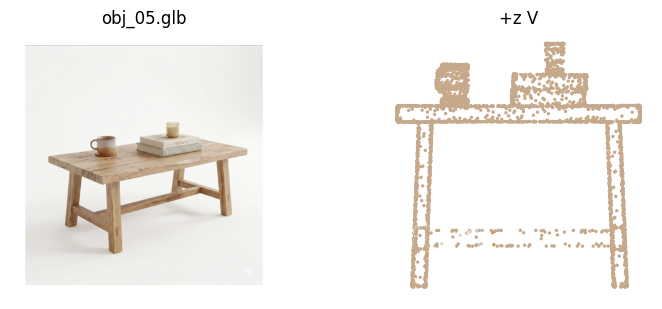

baked obj_05 +z


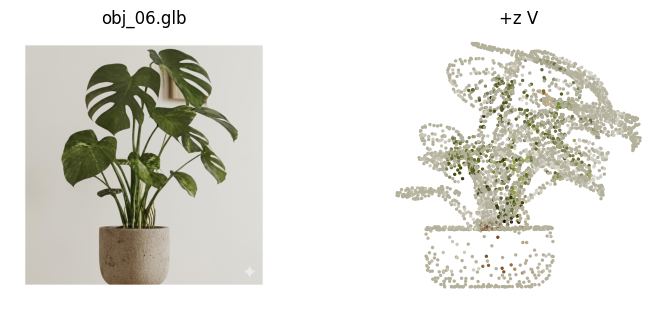

baked obj_06 +z


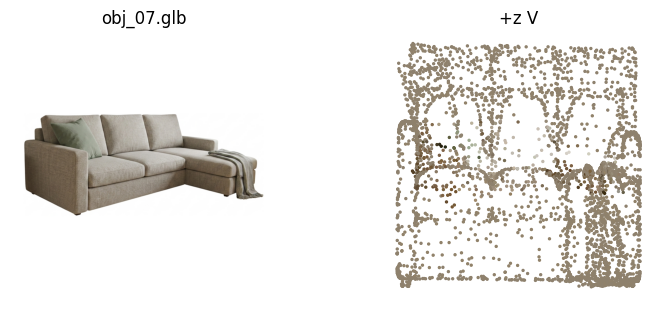

baked obj_07 +z
wrote texinfo.json -> {'obj_00': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}, 'obj_01': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}, 'obj_02': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}, 'obj_04': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}, 'obj_05': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}, 'obj_06': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}, 'obj_07': {'front_axis': 'z', 'front_sign': 1, 'up_axis': 'y', 'up_sign': 1}}


In [3]:
!pip install trimesh pillow numpy pygltflib -q
import os, glob, trimesh, numpy as np, pygltflib
from PIL import Image
import matplotlib.pyplot as plt

OUT="/content/outputs"
RAW=f"{OUT}/meshes_raw"      # per-object geometry GLBs (set to "/content" if yours are there)
OBJ=f"{OUT}/objects"         # extracted per-object photos
DST=f"{OUT}/meshes"; os.makedirs(DST, exist_ok=True)

FRONT="+z"          # default mesh axis pointing at the camera (worked for obj_04)
FLIP_U=False        # mirror left-right
FLIP_V=True         # flip up-down (your script's 1 - y_n)
SAT_SAMP=1.8        # saturation on projected colours  (drop to 1.0 for the beige sofa)
SAT_FILL=1.5        # saturation on the back-fill colour
PREVIEW=True

# fix the garbled ones here once you see their previews: name -> (FRONT, FLIP_U, FLIP_V)
OVERRIDE = {
    # "obj_05": ("+x", False, True),
    # "obj_06": ("-z", False, True),
}

AXI={"x":0,"y":1,"z":2}
def parse(f): s=1.0 if f[0]=="+" else -1.0; a=AXI[f[1]]; r=[i for i in (0,1,2) if i!=a]; return a,r[0],r[1],s
def boost(c,f): g=c.mean(1,keepdims=True); return np.clip(g+f*(c-g),0,255)

def bake(glb, png, out, front, flip_u, flip_v):
    photo=np.array(Image.open(png).convert("RGB"),np.float32); H,W=photo.shape[:2]
    bg=(photo[:,:,0]>220)&(photo[:,:,1]>220)&(photo[:,:,2]>220)
    fg=photo[~bg]; avg=fg.mean(0) if len(fg)>100 else photo.reshape(-1,3).mean(0)
    scene=trimesh.load(glb,force="scene"); mesh=next(iter(scene.geometry.values())); mesh.fix_normals()
    v=mesh.vertices; n=mesh.vertex_normals
    fa,ia,ib,sgn=parse(front); fvec=np.zeros(3); fvec[fa]=sgn; dot=n@fvec
    xn=(v[:,ia]-v[:,ia].min())/(np.ptp(v[:,ia])+1e-8)
    yn=(v[:,ib]-v[:,ib].min())/(np.ptp(v[:,ib])+1e-8)
    if flip_u: xn=1-xn
    px=np.clip((xn*(W-1)).astype(int),0,W-1)
    py=np.clip((((1-yn) if flip_v else yn)*(H-1)).astype(int),0,H-1)
    samp=photo[py,px].copy()
    wm=(samp[:,0]>220)&(samp[:,1]>220)&(samp[:,2]>220); samp[wm]=avg
    samp=boost(samp,SAT_SAMP)
    alpha=np.clip(dot,0,1)[:,None]
    fill=boost(np.tile(avg,(len(v),1)),SAT_FILL)
    blended=(alpha*samp+(1-alpha)*fill).clip(0,255).astype(np.uint8)
    vf=v.astype(np.float32); ff=mesh.faces.astype(np.uint32); nf=n.astype(np.float32)
    cf=np.hstack([blended/255.0,np.ones((len(blended),1),np.float32)]).astype(np.float32)
    blob=[b'']; bvs=[]; accs=[]
    def add(d,t=None):
        raw=d.tobytes(); off=len(blob[0]); blob[0]+=raw
        bv=pygltflib.BufferView(buffer=0,byteOffset=off,byteLength=len(raw))
        if t: bv.target=t
        bvs.append(bv); return len(bvs)-1
    def acc(bi,ct,cnt,at,d=None):
        a=pygltflib.Accessor(bufferView=bi,componentType=ct,count=cnt,type=at)
        if d is not None and d.ndim>1: a.min=d.min(0).tolist(); a.max=d.max(0).tolist()
        accs.append(a); return len(accs)-1
    IDX=acc(add(ff.flatten(),pygltflib.ELEMENT_ARRAY_BUFFER),pygltflib.UNSIGNED_INT,ff.size,pygltflib.SCALAR)
    POS=acc(add(vf,pygltflib.ARRAY_BUFFER),pygltflib.FLOAT,len(vf),pygltflib.VEC3,vf)
    NRM=acc(add(nf,pygltflib.ARRAY_BUFFER),pygltflib.FLOAT,len(nf),pygltflib.VEC3,nf)
    COL=acc(add(cf,pygltflib.ARRAY_BUFFER),pygltflib.FLOAT,len(cf),pygltflib.VEC4)
    # g=pygltflib.GLTF2(scene=0,scenes=[pygltflib.Scene(nodes=[0])],nodes=[pygltflib.Node(mesh=0)],
    #     meshes=[pygltflib.Mesh(primitives=[pygltflib.Primitive(
    #         attributes=pygltflib.Attributes(POSITION=POS,NORMAL=NRM,COLOR_0=COL),indices=IDX,material=0)])],
    #     materials=[pygltflib.Material(name="VertexColor",
    #         pbrMetallicRoughness=pygltflib.PbrMetallicRoughness(baseColorFactor=[1,1,1,1],metallicFactor=0.0,roughnessFactor=0.9),
    #         doubleSided=True)],
    #     accessors=accs,bufferViews=bvs,buffers=[pygltflib.Buffer(byteLength=len(blob[0]))])
    g=pygltflib.GLTF2(scene=0,scenes=[pygltflib.Scene(nodes=[0])],nodes=[pygltflib.Node(mesh=0)],
        meshes=[pygltflib.Mesh(primitives=[pygltflib.Primitive(
            attributes=pygltflib.Attributes(POSITION=POS,NORMAL=NRM,COLOR_0=COL),indices=IDX)])],
        accessors=accs,bufferViews=bvs,buffers=[pygltflib.Buffer(byteLength=len(blob[0]))])
    g.set_binary_blob(blob[0]); g.save(out)

    if PREVIEW:
        fig,ax=plt.subplots(1,2,figsize=(8,3.2))
        ax[0].imshow(photo.astype(np.uint8)); ax[0].set_title(os.path.basename(out)); ax[0].axis("off")
        ax[1].scatter(px[::4],H-py[::4],c=np.clip(blended[::4]/255.0,0,1),s=2)
        ax[1].set_aspect("equal"); ax[1].axis("off")
        ax[1].set_title(f"{front} {'U' if flip_u else ''}{'V' if flip_v else ''}"); plt.tight_layout(); plt.show()

# for mp in sorted(glob.glob(f"{RAW}/*.glb")):
#     name=os.path.splitext(os.path.basename(mp))[0]; png=f"{OBJ}/{name}.png"
#     if not os.path.exists(png): print("no photo for",name); continue
#     fr,fu,fv=OVERRIDE.get(name,(FRONT,FLIP_U,FLIP_V))
#     bake(mp,png,f"{DST}/{name}.glb",fr,fu,fv); print("baked",name,fr)
# print("done ->",DST)

import json
texinfo = {}
for mp in sorted(glob.glob(f"{RAW}/*.glb")):
    name=os.path.splitext(os.path.basename(mp))[0]; png=f"{OBJ}/{name}.png"
    if not os.path.exists(png): print("no photo for",name); continue
    fr,fu,fv=OVERRIDE.get(name,(FRONT,FLIP_U,FLIP_V))
    bake(mp,png,f"{DST}/{name}.glb",fr,fu,fv)
    fa,ia,ib,sgn=parse(fr)
    texinfo[name]={"front_axis":fr[1], "front_sign":int(sgn),
                   "up_axis":{0:'x',1:'y',2:'z'}[ib], "up_sign":1 if fv else -1}
    print("baked",name,fr)
json.dump(texinfo, open(f"{OUT}/texinfo.json","w"), indent=2)
print("wrote texinfo.json ->", texinfo)

In [4]:
# # C2 — placement: 3D fit + (PyTorch3D) differentiable silhouette refine, preserving SF3D textures
# import os, json, numpy as np, open3d as o3d, trimesh, cv2, torch
# from PIL import Image
# import torch.nn.functional as F
# OUT="/content/outputs"; meta=json.load(open(f"{OUT}/meta.json"))
# W=meta["width"]; Hh=meta["height"]; intr=np.array(meta["intrinsics"])
# dev="cuda" if torch.cuda.is_available() else "cpu"
# RENDER=256; W_SIL,W_3D,REG=1.0,0.4,0.02; N_REFINE=120; DROP_TO_FLOOR=True
# KEEP=globals().get("KEEP",set()); YAW_OVERRIDE=globals().get("YAW_OVERRIDE",{})

# USE_P3D=True
# try:
#     from pytorch3d.structures import Meshes, Pointclouds
#     from pytorch3d.renderer import (RasterizationSettings, MeshRasterizer, MeshRenderer, SoftSilhouetteShader, BlendParams)
#     from pytorch3d.utils import cameras_from_opencv_projection
#     from pytorch3d.loss import point_mesh_face_distance
# except Exception as e:
#     USE_P3D=False; print("PyTorch3D unavailable -> fast-silhouette fallback:", e)

# # floor plane (objects-above-plane)
# objpts=np.vstack([np.asarray(o3d.io.read_point_cloud(f"{OUT}/clusters/{o['id']}.ply").points)
#                   for o in meta["objects"] if os.path.exists(f"{OUT}/clusters/{o['id']}.ply")])
# rest=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(np.asarray(o3d.io.read_point_cloud(f"{OUT}/floor.ply").points))); bf=None
# for _ in range(4):
#     if len(rest.points)<500: break
#     pl,inl=rest.segment_plane(0.02,3,1000); rest=rest.select_by_index(inl,invert=True)
#     nn=np.array(pl[:3],float); dd=pl[3]; L=np.linalg.norm(nn); nn/=L; dd/=L
#     if np.mean(objpts@nn+dd>0)<0.5: nn,dd=-nn,-dd
#     s=np.mean((objpts@nn+dd)>-0.05)
#     if bf is None or s>bf[0]: bf=(s,nn,dd)
# n=bf[1]; d=bf[2]; print("floor up =",np.round(n,3))
# nt=torch.tensor(n,dtype=torch.float32,device=dev)
# Kt=torch.zeros(3,3,device=dev); Kt[0,1],Kt[0,2]=-nt[2],nt[1]; Kt[1,0],Kt[1,2]=nt[2],-nt[0]; Kt[2,0],Kt[2,1]=-nt[1],nt[0]
# I3=torch.eye(3,device=dev); Knp=Kt.cpu().numpy()
# def Ryaw(a): return I3+torch.sin(a)*Kt+(1-torch.cos(a))*(Kt@Kt)
# def Ryaw_np(a): return np.eye(3)+np.sin(a)*Knp+(1-np.cos(a))*(Knp@Knp)
# def rod_np(a,b):
#     a=a/np.linalg.norm(a); b=b/np.linalg.norm(b); v=np.cross(a,b); s=np.linalg.norm(v); c=np.dot(a,b)
#     if s<1e-8: return np.eye(3) if c>0 else np.diag([1,-1,-1.])
#     M=np.array([[0,-v[2],v[1]],[v[2],0,-v[0]],[-v[1],v[0],0]]); return np.eye(3)+M+M@M*((1-c)/(s*s))
# AXES=[(1,0,0),(-1,0,0),(0,1,0),(0,-1,0),(0,0,1),(0,0,-1)]

# scd=RENDER/max(W,Hh); rw,rh=int(round(W*scd)),int(round(Hh*scd))
# def project(V):
#     z=np.clip(V[:,2],1e-4,None)
#     return np.stack([(intr[0,0]*V[:,0]/z+intr[0,2])*W,(intr[1,1]*V[:,1]/z+intr[1,2])*Hh],1)
# def cheap_iou(V,faces,mask):
#     uv=project(V).astype(np.int32); im=np.zeros((Hh,W),np.uint8); cv2.fillPoly(im,uv[faces],1)
#     a=im.astype(bool); u=(a|mask).sum(); return (a&mask).sum()/u if u else 0.0
# if USE_P3D:
#     fx,fy,cx,cy=intr[0,0]*W*scd,intr[1,1]*Hh*scd,intr[0,2]*W*scd,intr[1,2]*Hh*scd
#     Kpix=torch.tensor([[[fx,0,cx],[0,fy,cy],[0,0,1.]]],dtype=torch.float32,device=dev)
#     cams=cameras_from_opencv_projection(torch.eye(3,device=dev)[None], torch.zeros(1,3,device=dev),
#                                         Kpix, torch.tensor([[rh,rw]],dtype=torch.float32,device=dev)).to(dev)
#     SIGMA=1e-4; blur=np.log(1./1e-4-1.)*SIGMA
#     rs=RasterizationSettings(image_size=(rh,rw),blur_radius=blur,faces_per_pixel=50,perspective_correct=False,bin_size=0)
#     renderer=MeshRenderer(rasterizer=MeshRasterizer(cameras=cams,raster_settings=rs),
#                           shader=SoftSilhouetteShader(blend_params=BlendParams(sigma=SIGMA,gamma=1e-4)))
#     def render_sil(V,Ft): return renderer(Meshes(verts=[V],faces=[Ft]))[0,...,3]

# scene=trimesh.Scene(); scene.add_geometry(trimesh.load(f"{OUT}/background_room.glb",force="mesh"),node_name="background")
# for o in meta["objects"]:
#     oid=o["id"]; mp=f"{OUT}/meshes/{oid}.glb"; cp=f"{OUT}/clusters/{oid}.ply"; mk=f"{OUT}/masks/{oid}.png"
#     if KEEP and oid not in KEEP: continue
#     if not (os.path.exists(mp) and os.path.exists(cp)): continue
#     cl=np.asarray(o3d.io.read_point_cloud(cp).points)
#     if len(cl)<30: continue
#     ctr=cl.mean(0); ext=np.linalg.norm(cl.max(0)-cl.min(0))
#     mesh=trimesh.load(mp,force="mesh")
#     vsrc=np.asarray(mesh.vertices,float); v0=vsrc-vsrc.mean(0)
#     faces=np.asarray(mesh.faces); base=ext/(np.linalg.norm(v0.max(0)-v0.min(0))+1e-9)
#     mask=None
#     if os.path.exists(mk):
#         mask=np.asarray(Image.open(mk).convert("L"))>127
#         if mask.shape!=(Hh,W): mask=cv2.resize(mask.astype(np.uint8),(W,Hh)).astype(bool)
#     clt=torch.tensor(cl-ctr,dtype=torch.float32,device=dev)
#     if len(clt)>4000: clt=clt[torch.randperm(len(clt),device=dev)[:4000]]
#     # ---- fast 3D init (up-axis + yaw + scale + planar trans) ----
#     best=None
#     for ax in AXES:
#         Rup=rod_np(np.array(ax,float),n); Rupt=torch.tensor(Rup,dtype=torch.float32,device=dev)
#         vt=torch.tensor(v0,dtype=torch.float32,device=dev)@Rupt.T
#         angs=torch.linspace(0,2*np.pi,12,device=dev)
#         with torch.no_grad():
#             gi=int(torch.stack([torch.cdist(clt,(vt*base)@Ryaw(a).T).min(1).values.mean() for a in angs]).argmin())
#         yaw=torch.tensor([float(angs[gi])],device=dev,requires_grad=True)
#         logs=torch.zeros(1,device=dev,requires_grad=True); tr=torch.zeros(3,device=dev,requires_grad=True)
#         opt=torch.optim.Adam([yaw,logs,tr],lr=0.05)
#         for _ in range(120):
#             opt.zero_grad()
#             vp=(vt*(base*torch.exp(logs)))@Ryaw(yaw[0]).T+tr
#             loss=torch.cdist(clt,vp).min(1).values.mean()+0.01*logs.pow(2).sum()+REG*tr.pow(2).sum()
#             loss.backward(); opt.step()
#         if best is None or loss.item()<best[0]:
#             best=(loss.item(),Rup,float(yaw.item()),base*float(torch.exp(logs).item()),tr.detach().cpu().numpy())
#     al,Rup,yaw,scl,tr=best
#     Rupt=torch.tensor(Rup,dtype=torch.float32,device=dev); v0t=torch.tensor(v0,dtype=torch.float32,device=dev); ctr_t=torch.tensor(ctr,dtype=torch.float32,device=dev)
#     # ---- differentiable silhouette refine (PyTorch3D) ----
#     if USE_P3D and mask is not None:
#         Ft=torch.tensor(faces,dtype=torch.int64,device=dev)
#         mask_s=torch.tensor(cv2.resize(mask.astype(np.uint8),(rw,rh)),dtype=torch.float32,device=dev)
#         yawp=torch.tensor([yaw],device=dev,requires_grad=True)
#         logp=torch.tensor([float(np.log(max(scl/base,1e-3)))],device=dev,requires_grad=True)
#         trp=torch.tensor(tr,dtype=torch.float32,device=dev,requires_grad=True)
#         opt=torch.optim.Adam([yawp,logp,trp],lr=0.02)
#         for it in range(N_REFINE):
#             opt.zero_grad()
#             V=(v0t@Rupt.T*(base*torch.exp(logp)))@Ryaw(yawp[0]).T+ctr_t+trp
#             with torch.no_grad():
#                 drop=-(V@nt+d).min() if DROP_TO_FLOOR else torch.tensor(0.,device=dev)
#             V=V+nt*drop
#             sil=render_sil(V,Ft).clamp(1e-6,1-1e-6)
#             inter=(sil*mask_s).sum(); dice=1-(2*inter+1)/(sil.sum()+mask_s.sum()+1); bce=F.binary_cross_entropy(sil,mask_s)
#             l3d=point_mesh_face_distance(Meshes(verts=[V],faces=[Ft]),Pointclouds([clt]))
#             loss=W_SIL*(0.75*dice+0.25*bce)+W_3D*l3d+REG*trp.pow(2).sum()
#             loss.backward(); opt.step()
#         yaw=float(yawp.item()); scl=base*float(torch.exp(logp).item()); tr=trp.detach().cpu().numpy()
#     elif mask is not None:
#         bestc=None                                            # fallback: 4-way yaw IoU disambiguation
#         for yc in [yaw,yaw+np.pi,yaw+np.pi/2,yaw-np.pi/2]:
#             Vw=((v0@Rup.T)*scl)@Ryaw_np(yc).T+ctr+tr; sh=-(Vw@n+d).min() if DROP_TO_FLOOR else 0.0
#             iou=cheap_iou(Vw+n*sh,faces,mask)
#             if bestc is None or iou>bestc[0]: bestc=(iou,yc)
#         yaw=bestc[1]
#     if oid in YAW_OVERRIDE: yaw=float(YAW_OVERRIDE[oid])
#     # ---- finalize + drop to floor, preserve SF3D texture ----
#     def xf(verts): return ((verts@Rup.T)*scl)@Ryaw_np(yaw).T+ctr+tr
#     Vraw=xf(v0); shift=-(Vraw@n+d).min() if DROP_TO_FLOOR else 0.0
#     nv=Vraw+n*shift
#     iou=cheap_iou(nv,faces,mask) if mask is not None else 0.0
#     print(f"{oid}: IoU {iou:.2f}  3D-init {al:.4f}  scale {scl:.3f}")
#     placed=mesh.copy(); placed.vertices=nv                    # keeps SF3D UV + texture
#     scene.add_geometry(placed, node_name=oid)
#     if mask is not None:
#         sg=np.zeros((Hh,W),np.uint8); cv2.fillPoly(sg,project(nv).astype(np.int32)[faces],1)
#         ov=np.zeros((Hh,W,3),np.uint8); ov[...,0]=mask.astype(np.uint8)*255; ov[...,1]=sg*255
#         Image.fromarray(ov).save(f"{OUT}/debugfit_{oid}.png")
# scene.export(f"{OUT}/scene_final.glb")
# print("exported scene_final.glb | mode:", "PyTorch3D silhouette" if USE_P3D else "fallback")



# C2 — placement with CAMERA-FACING orientation (front->camera, up->floor) + small-yaw silhouette refine
# TripoSG meshes (vertex-coloured) or textured meshes; preserves the mesh's existing visual.
import os, json, numpy as np, open3d as o3d, trimesh, cv2, torch
from PIL import Image
import torch.nn.functional as F

OUT="/content/outputs"
meta=json.load(open(f"{OUT}/meta.json"))
W=meta["width"]; Hh=meta["height"]; intr=np.array(meta["intrinsics"])
dev="cuda" if torch.cuda.is_available() else "cpu"

RENDER=256; W_SIL,W_3D,REG=1.0,0.5,0.02
N_INIT=150; N_REFINE=120; DROP_TO_FLOOR=True
YAW_LIMIT=np.deg2rad(60)                         # refine may swing facing at most this far from the camera prior
KEEP=globals().get("KEEP",set())
YAW_OVERRIDE=globals().get("YAW_OVERRIDE",{})    # oid -> EXTRA yaw (radians) about floor-up, added on top (e.g. np.pi to flip)

# ---- shared front/up convention (must match Notebook B texturing); default TripoSG = +Z front, +Y up ----
AXVEC={"x":np.array([1.,0,0]),"y":np.array([0,1.,0]),"z":np.array([0,0,1.])}
texinfo=json.load(open(f"{OUT}/texinfo.json")) if os.path.exists(f"{OUT}/texinfo.json") else {}
def front_up_for(oid):
    ti=texinfo.get(oid,{})
    return (float(ti.get("front_sign",1))*AXVEC[ti.get("front_axis","z")],
            float(ti.get("up_sign",1))*AXVEC[ti.get("up_axis","y")])

# ---- PyTorch3D (optional) ----
USE_P3D=True
try:
    from pytorch3d.structures import Meshes, Pointclouds
    from pytorch3d.renderer import (RasterizationSettings, MeshRasterizer, MeshRenderer, SoftSilhouetteShader, BlendParams)
    from pytorch3d.utils import cameras_from_opencv_projection
    from pytorch3d.loss import point_mesh_face_distance
except Exception as e:
    USE_P3D=False; print("PyTorch3D unavailable -> fallback (IoU yaw search):", e)

# ---- floor plane (objects above) ----
objpts=np.vstack([np.asarray(o3d.io.read_point_cloud(f"{OUT}/clusters/{o['id']}.ply").points)
                  for o in meta["objects"] if os.path.exists(f"{OUT}/clusters/{o['id']}.ply")])
rest=o3d.geometry.PointCloud(o3d.utility.Vector3dVector(
        np.asarray(o3d.io.read_point_cloud(f"{OUT}/floor.ply").points))); bf=None
for _ in range(4):
    if len(rest.points)<500: break
    pl,inl=rest.segment_plane(0.02,3,1000); rest=rest.select_by_index(inl,invert=True)
    nn=np.array(pl[:3],float); dd=pl[3]; L=np.linalg.norm(nn); nn/=L; dd/=L
    if np.mean(objpts@nn+dd>0)<0.5: nn,dd=-nn,-dd
    s=np.mean((objpts@nn+dd)>-0.05)
    if bf is None or s>bf[0]: bf=(s,nn,dd)
n=bf[1]; d=bf[2]; print("floor up =",np.round(n,3))
nt=torch.tensor(n,dtype=torch.float32,device=dev)
Kt=torch.zeros(3,3,device=dev); Kt[0,1],Kt[0,2]=-nt[2],nt[1]; Kt[1,0],Kt[1,2]=nt[2],-nt[0]; Kt[2,0],Kt[2,1]=-nt[1],nt[0]
I3=torch.eye(3,device=dev); Knp=Kt.cpu().numpy()
def Ryaw(a):    return I3+torch.sin(a)*Kt+(1-torch.cos(a))*(Kt@Kt)              # rotation about floor-up
def Ryaw_np(a): return np.eye(3)+np.sin(a)*Knp+(1-np.cos(a))*(Knp@Knp)

# ---- camera-facing world rotation: object front -> back toward camera, object up -> floor up ----
def cam_facing_R(ctr, front_mesh, up_mesh):
    up_w=n/np.linalg.norm(n)
    cam_dir=ctr/(np.linalg.norm(ctr)+1e-9)
    front_w=-cam_dir; front_w=front_w-up_w*(front_w@up_w)
    if np.linalg.norm(front_w)<1e-6: front_w=np.array([1.,0,0])-up_w*up_w[0]
    front_w/=np.linalg.norm(front_w)
    right_w=np.cross(up_w,front_w); right_w/=np.linalg.norm(right_w)
    fm=front_mesh/np.linalg.norm(front_mesh); um=up_mesh/np.linalg.norm(up_mesh)
    rm=np.cross(um,fm); rm/=np.linalg.norm(rm); um=np.cross(fm,rm)
    Rm=np.stack([rm,um,fm],1); Rw=np.stack([right_w,up_w,front_w],1)
    return Rw@Rm.T

# ---- projection helpers (intr is normalized -> multiply by W/H) ----
scd=RENDER/max(W,Hh); rw,rh=int(round(W*scd)),int(round(Hh*scd))
def project(V):
    z=np.clip(V[:,2],1e-4,None)
    return np.stack([(intr[0,0]*V[:,0]/z+intr[0,2])*W,(intr[1,1]*V[:,1]/z+intr[1,2])*Hh],1)
def cheap_iou(V,faces,mask):
    uv=project(V).astype(np.int32); im=np.zeros((Hh,W),np.uint8); cv2.fillPoly(im,uv[faces],1)
    a=im.astype(bool); u=(a|mask).sum(); return (a&mask).sum()/u if u else 0.0
if USE_P3D:
    fx,fy,cx,cy=intr[0,0]*W*scd,intr[1,1]*Hh*scd,intr[0,2]*W*scd,intr[1,2]*Hh*scd
    Kpix=torch.tensor([[[fx,0,cx],[0,fy,cy],[0,0,1.]]],dtype=torch.float32,device=dev)
    cams=cameras_from_opencv_projection(torch.eye(3,device=dev)[None], torch.zeros(1,3,device=dev),
                                        Kpix, torch.tensor([[rh,rw]],dtype=torch.float32,device=dev)).to(dev)
    SIGMA=1e-4; blur=np.log(1./1e-4-1.)*SIGMA
    rs=RasterizationSettings(image_size=(rh,rw),blur_radius=blur,faces_per_pixel=50,perspective_correct=False,bin_size=0)
    renderer=MeshRenderer(rasterizer=MeshRasterizer(cameras=cams,raster_settings=rs),
                          shader=SoftSilhouetteShader(blend_params=BlendParams(sigma=SIGMA,gamma=1e-4)))
    def render_sil(V,Ft): return renderer(Meshes(verts=[V],faces=[Ft]))[0,...,3]

# ---- assemble ----
scene=trimesh.Scene()
scene.add_geometry(trimesh.load(f"{OUT}/background_room.glb",force="mesh"),node_name="background")

for o in meta["objects"]:
    oid=o["id"]; mp=f"{OUT}/meshes/{oid}.glb"; cp=f"{OUT}/clusters/{oid}.ply"; mk=f"{OUT}/masks/{oid}.png"
    if KEEP and oid not in KEEP: continue
    if not (os.path.exists(mp) and os.path.exists(cp)): continue
    cl=np.asarray(o3d.io.read_point_cloud(cp).points)
    if len(cl)<30: continue
    ctr=cl.mean(0); ext=np.linalg.norm(cl.max(0)-cl.min(0))
    # ---- load mesh with color preservation ----
    mesh = trimesh.load(mp, force='mesh', process=False)
    if mesh is None or len(mesh.vertices) == 0:
        loaded = trimesh.load(mp)
        if isinstance(loaded, trimesh.Scene):
            for g in loaded.geometry.values():
                if isinstance(g, trimesh.Trimesh) and len(g.vertices) > 0:
                    mesh = g
                    break
    if mesh is None or len(mesh.vertices) == 0:
        print(f"Skipping {oid} – no geometry")
        continue

    print(f"{oid}: visual = {mesh.visual.kind}")  # 'texture' or 'vertex' or 'empty'
    vsrc = np.asarray(mesh.vertices, float)
    v0 = vsrc - vsrc.mean(0)
    faces = np.asarray(mesh.faces)
    base = ext / (np.linalg.norm(v0.max(0) - v0.min(0)) + 1e-9)
    # ---- ensure colour: if the mesh has no real colour/texture, project it from the object photo ----
    def _has_color(m):
        if isinstance(m.visual, trimesh.visual.TextureVisuals): return True
        vc = getattr(m.visual, "vertex_colors", None)
        return vc is not None and len(vc) > 0 and float(np.asarray(vc)[:, :3].std()) > 8
    _photo = f"{OUT}/objects/{oid}.png"
    if (not _has_color(mesh)) and os.path.exists(_photo):
        fm_loc, _ = front_up_for(oid)
        arr = np.array(Image.open(_photo).convert("RGB")).astype(np.float32); Hp, Wp = arr.shape[:2]
        bgm = (arr[:, :, 0] > 235) & (arr[:, :, 1] > 235) & (arr[:, :, 2] > 235)
        fgp = arr[~bgm]; avg = np.median(fgp, 0) if len(fgp) > 100 else np.median(arr.reshape(-1, 3), 0)
        fa = int(np.argmax(np.abs(fm_loc))); ij = [a for a in (0, 1, 2) if a != fa]
        u = (v0[:, ij[0]] - v0[:, ij[0]].min()) / (np.ptp(v0[:, ij[0]]) + 1e-9)
        w = (v0[:, ij[1]] - v0[:, ij[1]].min()) / (np.ptp(v0[:, ij[1]]) + 1e-9)
        pu = np.clip((u * (Wp - 1)).astype(int), 0, Wp - 1)
        pv = np.clip(((1 - w) * (Hp - 1)).astype(int), 0, Hp - 1)
        samp = arr[pv, pu].copy()
        wm = (samp[:, 0] > 235) & (samp[:, 1] > 235) & (samp[:, 2] > 235); samp[wm] = avg
        a = np.clip(mesh.vertex_normals @ (fm_loc / np.linalg.norm(fm_loc)), 0, 1)[:, None]  # front sharp, back->avg
        col = (a * samp + (1 - a) * avg).clip(0, 255).astype(np.uint8)
        mesh.visual = trimesh.visual.ColorVisuals(
            mesh=mesh, vertex_colors=np.hstack([col, np.full((len(col), 1), 255, np.uint8)]))
        print(f"   {oid}: projected colour from photo")
    mask=None
    if os.path.exists(mk):
        mask=np.asarray(Image.open(mk).convert("L"))>127
        if mask.shape!=(Hh,W): mask=cv2.resize(mask.astype(np.uint8),(W,Hh)).astype(bool)

    front_mesh,up_mesh=front_up_for(oid)
    R_init=cam_facing_R(ctr,front_mesh,up_mesh)
    R_init_t=torch.tensor(R_init,dtype=torch.float32,device=dev)
    v0t=torch.tensor(v0,dtype=torch.float32,device=dev)
    ctr_t=torch.tensor(ctr,dtype=torch.float32,device=dev)
    clt=torch.tensor(cl,dtype=torch.float32,device=dev)
    if len(clt)>4000: clt=clt[torch.randperm(len(clt),device=dev)[:4000]]

    yaw =torch.zeros(1,device=dev,requires_grad=True)   # small correction about floor-up
    logs=torch.zeros(1,device=dev,requires_grad=True)   # log scale multiplier
    tr  =torch.zeros(3,device=dev,requires_grad=True)   # residual translation
    def world(y,ls,t): return ((v0t*(base*torch.exp(ls)))@R_init_t.T)@Ryaw(y[0]).T+ctr_t+t

    # phase 1 — 3D chamfer fit (position/scale + small yaw); facing held near the camera prior
    opt=torch.optim.Adam([yaw,logs,tr],lr=0.05)
    for _ in range(N_INIT):
        opt.zero_grad()
        loss=torch.cdist(clt,world(yaw,logs,tr)).min(1).values.mean()+0.01*logs.pow(2).sum()+REG*tr.pow(2).sum()
        loss.backward(); opt.step()
        with torch.no_grad(): yaw.clamp_(-YAW_LIMIT,YAW_LIMIT)
    init3d=float(loss.item())

    # phase 2 — differentiable silhouette refine
    if USE_P3D and mask is not None:
        Ft=torch.tensor(faces,dtype=torch.int64,device=dev)
        mask_s=torch.tensor(cv2.resize(mask.astype(np.uint8),(rw,rh)),dtype=torch.float32,device=dev)
        opt=torch.optim.Adam([yaw,logs,tr],lr=0.02)
        for _ in range(N_REFINE):
            opt.zero_grad()
            V=world(yaw,logs,tr)
            with torch.no_grad(): drop=-(V@nt+d).min() if DROP_TO_FLOOR else torch.tensor(0.,device=dev)
            V=V+nt*drop
            sil=render_sil(V,Ft).clamp(1e-6,1-1e-6)
            inter=(sil*mask_s).sum(); dice=1-(2*inter+1)/(sil.sum()+mask_s.sum()+1); bce=F.binary_cross_entropy(sil,mask_s)
            l3d=point_mesh_face_distance(Meshes(verts=[V],faces=[Ft]),Pointclouds([clt]))
            loss=W_SIL*(0.75*dice+0.25*bce)+W_3D*l3d+REG*tr.pow(2).sum()+0.01*logs.pow(2).sum()
            loss.backward(); opt.step()
            with torch.no_grad(): yaw.clamp_(-YAW_LIMIT,YAW_LIMIT)
    elif mask is not None:
        best=None
        for dy in np.deg2rad([-40,-25,-12,0,12,25,40]):
            with torch.no_grad(): Vn=world(torch.tensor([float(yaw)+dy],device=dev),logs,tr).cpu().numpy()
            sh=-(Vn@n+d).min() if DROP_TO_FLOOR else 0.0
            iou=cheap_iou(Vn+n*sh,faces,mask)
            if best is None or iou>best[0]: best=(iou,float(yaw)+dy)
        yaw=torch.tensor([best[1]],device=dev)

    yaw_extra=float(YAW_OVERRIDE.get(oid,0.0))
    s_final=base*np.exp(float(logs)); tr_np=tr.detach().cpu().numpy()
    def xf(verts): return ((verts*s_final)@R_init.T)@Ryaw_np(float(yaw)+yaw_extra).T+ctr+tr_np
    Vraw=xf(v0); shift=-(Vraw@n+d).min() if DROP_TO_FLOOR else 0.0
    nv=Vraw+n*shift
    iou=cheap_iou(nv,faces,mask) if mask is not None else 0.0
    print(f"{oid}: IoU {iou:.2f} | 3D-init {init3d:.4f} | scale {s_final:.3f} | yaw {np.rad2deg(float(yaw)+yaw_extra):+.0f}deg")
    placed=mesh.copy(); placed.vertices=nv                  # keeps vertex colours / texture
    scene.add_geometry(placed,node_name=oid)
    if mask is not None:
        sg=np.zeros((Hh,W),np.uint8); cv2.fillPoly(sg,project(nv).astype(np.int32)[faces],1)
        ov=np.zeros((Hh,W,3),np.uint8); ov[...,0]=mask.astype(np.uint8)*255; ov[...,1]=sg*255
        Image.fromarray(ov).save(f"{OUT}/debugfit_{oid}.png")

scene.export(f"{OUT}/scene_final.glb")
print("exported scene_final.glb | mode:", "PyTorch3D silhouette" if USE_P3D else "fallback IoU")

floor up = [ 0.025 -0.999 -0.041]
obj_00: visual = vertex


/tmp/ipykernel_10221/1345964653.py:334: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  s_final=base*np.exp(float(logs)); tr_np=tr.detach().cpu().numpy()


obj_00: IoU 0.05 | 3D-init 0.0227 | scale 0.529 | yaw -29deg
obj_01: visual = vertex
obj_01: IoU 0.23 | 3D-init 0.0561 | scale 0.953 | yaw -60deg
obj_02: visual = vertex
obj_02: IoU 0.57 | 3D-init 0.0104 | scale 0.196 | yaw +32deg
obj_04: visual = vertex
obj_04: IoU 0.09 | 3D-init 0.0320 | scale 0.429 | yaw +60deg
obj_05: visual = vertex
obj_05: IoU 0.12 | 3D-init 0.0611 | scale 0.947 | yaw +35deg
obj_06: visual = vertex
obj_06: IoU 0.00 | 3D-init 0.0292 | scale 0.413 | yaw -60deg
obj_07: visual = vertex
obj_07: IoU 0.29 | 3D-init 0.0486 | scale 1.107 | yaw +60deg
exported scene_final.glb | mode: PyTorch3D silhouette


In [6]:
# Recolour placed objects with EXACT colours from the ORIGINAL room photo (camera projection + z-buffer)
import json, numpy as np, trimesh, cv2
from PIL import Image

OUT="/content/outputs"
meta=json.load(open(f"{OUT}/meta.json")); W=meta["width"]; Hh=meta["height"]; intr=np.array(meta["intrinsics"])

PHOTO_PATH = f"/content/media_living_room.png"     # <-- set to your ORIGINAL room photo (the input to Notebook A)
photo=np.array(Image.open(PHOTO_PATH).convert("RGB"))
if photo.shape[:2]!=(Hh,W): photo=cv2.resize(photo,(W,Hh))
photo=photo.astype(np.float32)

def proj(V):
    z=np.clip(V[:,2],1e-4,None)
    px=(intr[0,0]*V[:,0]/z+intr[0,2])*W; py=(intr[1,1]*V[:,1]/z+intr[1,2])*Hh
    return px,py,z

scene=trimesh.load(f"{OUT}/scene_final.glb")
geoms=scene.dump()                                   # world-space trimeshes (transforms baked)
objs=[g for g in geoms if isinstance(g.visual, trimesh.visual.color.ColorVisuals)]   # vertex-coloured = the objects
print(len(objs), "object meshes to recolour (background + textured meshes left untouched)")

# 1) global nearest-surface depth buffer across all objects (vertex-level)
Z=np.full((Hh,W), np.inf, np.float32); cache=[]
for g in objs:
    v=np.asarray(g.vertices,float); px,py,z=proj(v)
    pxi=np.clip(px.astype(int),0,W-1); pyi=np.clip(py.astype(int),0,Hh-1)
    np.minimum.at(Z,(pyi,pxi),z.astype(np.float32))
    cache.append((g,v,pxi,pyi,z))

# 2) sample the photo for vertices that face the camera AND are the front-most surface
TOL=0.04
for g,v,pxi,pyi,z in cache:
    tocam=-v/(np.linalg.norm(v,axis=1,keepdims=True)+1e-9)
    facing=(g.vertex_normals*tocam).sum(1)
    vis=(facing>0.05) & (z <= Z[pyi,pxi]*(1+TOL))
    cur=np.asarray(g.visual.vertex_colors)[:,:3].astype(np.float32)
    cur[vis]=photo[pyi,pxi][vis]                      # EXACT original-photo colour on visible parts
    g.visual=trimesh.visual.ColorVisuals(mesh=g,
                vertex_colors=np.hstack([cur.clip(0,255).astype(np.uint8), np.full((len(v),1),255,np.uint8)]))

trimesh.Scene(geoms).export(f"{OUT}/scene_final_recolored.glb")
print("saved -> scene_final_recolored.glb")

8 object meshes to recolour (background + textured meshes left untouched)
saved -> scene_final_recolored.glb
